# 06 · Aer eğitimi → IBM donanımında test

**Amaç:** Eğitimi yerelde yapıp öğrenilen parametreleri donanıma aktararak kuyruk ve donanım kullanımını azaltmak.

**Okuma notu:** İlk donanım değerlendirmesi yalnız 8 örnektir. Aynı test alt kümesinde seçilen eşikle hesaplanan %75 bağımsız test sonucu değildir. Sonraki bazı denemeler KeyboardInterrupt ile kesilmiştir.

**Durum:** Staj çalışması arşivi. Aşağıdaki çıktılar ZIP içinde kayıtlı geçmiş çalıştırmalara aittir; bu yayına hazırlık sırasında üretilmiş yeni deney sonuçları değildir. Deney kodu ve eski açıklamalar gelişim sürecini göstermek için korunmuştur; yöntem düzeltmeleri ve sınırlılıklar için [çalışma rehberini](../../docs/CALISMA_REHBERI.md), [sonuçları](../../docs/SONUCLAR.md) ve [yöntem incelemesini](../../docs/YONTEM_VE_SINIRLAR.md) okuyun.

**English:** Historical internship experiment. See the [English overview](../../README_EN.md). Saved outputs are historical evidence, not a fresh reproducibility claim.



## Hedef: Basit bir QNN ile iris veri kümesi üzerinde 2'li sınıflandırma yaparak IBM Quantum Bilgisayarı üzerinde çalıştırmak.

Eğitim ve yoğun denemeleri AerSimulator ile, inference/ölçüm kısmını IBM cihazında yapacağız.

Bu adımda tek tek job atmak yerine batch çalıştıracağız (zaman tasarrufu).

In [ ]:
import sklearn
import qiskit
import numpy as np
import matplotlib

print("scikit-learn version:", {sklearn.__version__})
print("Qiskit version:", {qiskit.__version__})
print("NumPy version:", {np.__version__})
print("Matplotlib version:", {matplotlib.__version__})

#scikit-learn version: {'1.7.1'}
#Qiskit version: {'1.2.4'}
#NumPy version: {'2.1.3'}
#Matplotlib version: {'3.10.5'}

scikit-learn version: {'1.7.1'}
Qiskit version: {'1.2.4'}
NumPy version: {'2.1.3'}
Matplotlib version: {'3.10.5'}


IBM donanımına erişim artık Qiskit Runtime ile ve SamplerV2 / EstimatorV2 primitifleri üzerinden yapılıyor.


### 🔑 IBM Quantum Hesap Bağlantısı (IBM Cloud Üzerinden)

1. **API Key Oluştur**  
   - IBM Cloud > IAM > API Keys > “Create API Key”  

2. **Instance Yarat**  
   - IBM Quantum Platform > Service Instance oluştur  
   - Instance detaylarından **CRN** değerini kopyala  

3. **Hesabı Kaydet**   
   Terminal’de şu komutu çalıştır:  

   ```bash
   python - <<'PY'
   from qiskit_ibm_runtime import QiskitRuntimeService
   QiskitRuntimeService.save_account(
       channel="ibm_cloud",
       token="BURAYA_API_KEY",
       instance="BURAYA_INSTANCE_CRN",
       overwrite=True
   )
   print("✅ IBM Cloud hesabı kaydedildi.")
   PY
  

Bu işlemin sonunda artık IBM Quantum cihazlarına bağlanabilir, devrelerini gerçek donanımda çalıştırabilirsin.

In [ ]:
import qiskit, qiskit_aer, qiskit_ibm_runtime
print("Qiskit:", qiskit.__version__)          # 1.2.4
print("Aer:", qiskit_aer.__version__)         # 0.16.0
print("Runtime:", qiskit_ibm_runtime.__version__)  # 0.29.0

## v1'de imza ~ Sampler(backend=None, options=None, session=None)


Qiskit: 1.2.4
Aer: 0.16.0
Runtime: 0.29.0


In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

N = 4
INSTANCE = "YOUR_INSTANCE_CRN"
# IBM Cloud'da oluşturduğun Qiskit Runtime instance CRN

service = QiskitRuntimeService(channel="ibm_cloud", instance=INSTANCE)

# Gerçek cihaz adayları (operational ve en az 4 qubit)
candidates = service.backends(simulator=False, operational=True)
def num_qubits(b):
    return getattr(b, "num_qubits", getattr(getattr(b, "configuration", lambda: None)(), "n_qubits", 0))
candidates = [b for b in candidates if num_qubits(b) >= N]
print("Erişilebilir cihazlar:", [(b.name, num_qubits(b)) for b in candidates])

# Kuyruğu en kısa olanı seç
def queue_len(b):
    try:
        st = b.status()
        return getattr(st, "pending_jobs", getattr(st, "queue_size", 10**9))
    except Exception:
        return 10**9

backend = None
if candidates:
    candidates.sort(key=queue_len)
    backend = candidates[0]

if backend is None:
    backend = service.backend("ibmq_qasm_simulator")
    print("Uygun gerçek cihaz yok → simülatör seçildi.")

print(f"Seçilen backend: {backend.name} | Qubit sayısı: {num_qubits(backend)}")


Erişilebilir cihazlar: [('ibm_brisbane', 127), ('ibm_torino', 133)]
Seçilen backend: ibm_brisbane | Qubit sayısı: 127


Güzel, cihazlara erişimimiz var ve ibm_brisbane bağlanabiliriz.

In [ ]:
# Servise bağlanıp eriştiğimız cihazı 'backend' nesnesi olarak alıyoruz

INSTANCE = "YOUR_INSTANCE_CRN"

service = QiskitRuntimeService(channel="ibm_cloud", instance=INSTANCE)

backend = service.backend("ibm_brisbane")
print("Backend:", backend.name)


Backend: ibm_brisbane


In [ ]:
# Devre kurmak ve parametrizasyon için temel importlar
import numpy as np, time
from sklearn import datasets, model_selection
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

from qiskit.circuit import QuantumCircuit, QuantumRegister, ClassicalRegister, ParameterVector
from qiskit import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler, Options
from qiskit_aer import AerSimulator

N = 4  # 4 qubit kullanacağız

In [ ]:
# Veri hazırlığı ve ölçekleme (0, π) — pratik hazırlık

# 1) Iris (binary: ilk 100 kayıt = Setosa(0), Versicolor(1))
iris = datasets.load_iris()
X = iris.data[:100]
Y = iris.target[:100]

# 2) Train/Test böl
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(
    X, Y, test_size=0.33, random_state=42, stratify=Y
)

# 3) Feature scaling: [0, π]  → RX açıları için uygun
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# 4) Hızlı kontroller (N = 4 ile uyum?)
assert X_train_s.shape[1] == 4, "N=4 bekleniyordu."
assert np.all((X_train_s >= 0) & (X_train_s <= np.pi + 1e-9)), "Özellikler [0, π] aralığında olmalı."

print("X_train_s şekli:", X_train_s.shape, "| Örnek aralık:", (X_train_s.min(), X_train_s.max()))


X_train_s şekli: (67, 4) | Örnek aralık: (np.float64(0.0), np.float64(3.141592653589794))


**assert <şart>, "Hata mesajı"**

Eğer <şart> doğruysa (True) hiçbir şey olmaz, kod normal çalışmaya devam eder.

Eğer <şart> yanlışsa (False) bir AssertionError fırlatır ve arkasındaki hata mesajını gösterir.



In [ ]:

def feature_map(X_or_phi):
    q = QuantumRegister(N, "q")
    c = ClassicalRegister(1, "c")   # sadece q0'ı ölçeceğiz
    qc = QuantumCircuit(q, c, name="feature_map")
    for i, x in enumerate(X_or_phi):
        qc.rx(x, i)
    return qc, c

def variational_circuit(qc, theta):
    for i in range(N-1):
        qc.cx(i, i+1)
    qc.cx(N-1, 0)
    for i in range(N):
        qc.ry(theta[i], i)
    return qc


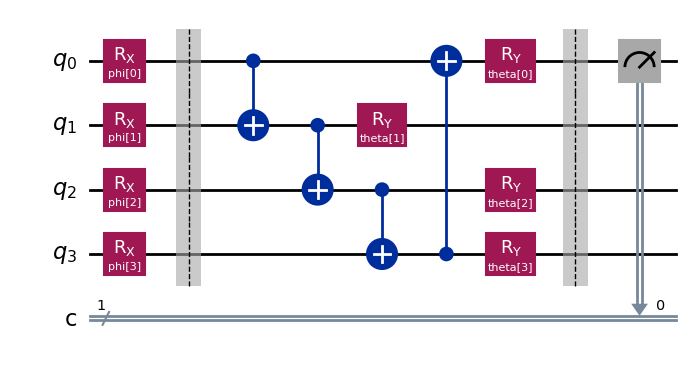

In [ ]:
#Parametrik şablon (phi/theta) + ölçüm
#Veriyi/parametreyi sonradan bağlayacağız.

phi   = ParameterVector('phi', N)     # veri parametreleri
theta = ParameterVector('theta', N)   # öğrenilebilir parametreler

qc, c = feature_map(phi)              #  feature_map()
qc.barrier()
qc = variational_circuit(qc, theta)   #  variational_circuit()
qc.barrier()
qc.measure(0, c[0])
                  # sadece q0'ı ölç → p(1)
qc.draw("mpl")  # Devreyi görselleştir

In [ ]:
#Hedefe göre transpile: HW ve SIM için ayrı ayrı yaparız

# QPU kapı seti ≠ AER kapı seti;
# Bu yüzdden iki şablon hazırlıyoruz.

# HW (ör. ibm_brisbane) için
tqc_hw = transpile(
    qc, backend=backend,
    optimization_level=3,       # 1 yerine 3: daha sığ devre
    layout_method="sabre",
    seed_transpiler=42
)
# SIM için
backend_sim = AerSimulator()
tqc_sim = transpile(qc, backend=backend_sim, optimization_level=1)

print("HW depth:", tqc_hw.depth(), "| SIM depth:", tqc_sim.depth())


HW depth: 50 | SIM depth: 7


In [ ]:
def quantum_nn_sim(x_vals, theta_vals, shots=2048):
    bind = {phi[i]: float(x_vals[i]) for i in range(N)}
    bind |= {theta[j]: float(theta_vals[j]) for j in range(N)}
    circ = tqc_sim.assign_parameters(bind, inplace=False)
    job = backend_sim.run(circ, shots=shots, seed_simulator=42)
    counts = job.result().get_counts()
    total = sum(counts.values()) or 1
    return counts.get('1', 0)/total

#Sim’de çalışan quantum_nn_sim (hızlı deneme/eğitim)
# Eğitim ve hızlı test için AER kullanıyoruz

In [ ]:
#Loss / Gradient / Accuracy (sim ile)
#Daha önceki denememdeki QNN eğitim iskeletini bozmadan kullanıyorum

# Loss MSE
def loss(pred, target):
    return (pred - target)**2

# Gradient (Finite Difference)
def gradient_fd_sim(x, y, theta_vals, delta=1e-2, shots=1024):
    g = np.zeros_like(theta_vals, float)
    for i in range(len(theta_vals)):
        thp = theta_vals.copy(); thp[i]+=delta
        thm = theta_vals.copy(); thm[i]-=delta
        p_plus  = quantum_nn_sim(x, thp, shots=shots)
        p_minus = quantum_nn_sim(x, thm, shots=shots)
        g[i] = ((p_plus - y)**2 - (p_minus - y)**2)/(2*delta)
    return g


# Accuracy
def accuracy_sim(X, Y, theta_vals, shots=1500, threshold=0.5):
    correct=0
    for x,y in zip(X,Y):
        p1 = quantum_nn_sim(x, theta_vals, shots=shots)
        correct += int((p1>=threshold) == int(y))
    return correct/len(Y)


In [ ]:
# Burada düzeltme yapıldı, train_simple_qnn
# (ileri geçiş quantum_nn, türev gradient_fd_sim) ---
import numpy as np

def train_simple_qnn(X_train_s, Y_train, X_test_s, Y_test,
                     epochs=10, eta=0.05, theta_init='random',
                     delta=1e-2, shots_grad=1024):
    """
    Basit QNN eğitimi (finite-difference gradient).
    - İleri geçiş için: quantum_nn(X, theta)  --> (sen üstte alias verdin: quantum_nn_sim)
    - Türev için: gradient_fd_sim(X, Y, theta, delta, shots_grad)
    """
    # Başlangıç thetası (DÜZELTME: random/ones doğru eşleştirildi)
    if theta_init == 'random':
        theta = np.random.rand(N).astype(float) * np.pi
    elif theta_init == 'ones':
        theta = np.ones(N, dtype=float)
    else:
        raise ValueError("theta_init 'random' veya 'ones' olmalı")

    loss_list, train_acc_list, test_acc_list = [], [], []
    print("Epoch\tLoss\tTrainAcc\tTestAcc")
    print("-"*44)

    for epoch in range(epochs):
        # SGD için karıştır
        idx = np.random.permutation(len(Y_train))
        X_tr = X_train_s[idx]; Y_tr = Y_train[idx]

        loss_tmp = []
        for X_i, Y_i in zip(X_tr, Y_tr):
            # 1) İleri geçiş: p(1)
            p1 = quantum_nn_sim(X_i, theta)  # DÜZGÜN: quantum_nn (sim alias)
            # 2) Kayıp
            ell = loss(p1, int(Y_i))
            loss_tmp.append(float(ell))
            # 3) Türev (finite-difference, merkez fark)
            g = gradient_fd_sim(X_i, int(Y_i), theta, delta=delta, shots=shots_grad)
            # 4) Güncelleme
            theta = theta - eta * g

        # Epoch sonu metrikler
        avg_loss = float(np.mean(loss_tmp)) if loss_tmp else 0.0
        train_acc = accuracy_sim(X_train_s, Y_train, theta, shots=1200, threshold=0.5)
        test_acc  = accuracy_sim(X_test_s,  Y_test,  theta, shots=1200, threshold=0.5)
        loss_list.append(avg_loss); train_acc_list.append(train_acc); test_acc_list.append(test_acc)
        print(f"{epoch:3d}\t{avg_loss:.3f}\t{train_acc:8.3f}\t{test_acc:7.3f}")

    return theta, loss_list, train_acc_list, test_acc_list


In [ ]:
#Eğitim (simde) → θ bul
# θ’yı simde öğren, QPU’da inference yap.

# Senin eğitim fonksiyonun quantum_nn adını bekliyor → bir alias veriyoruz
quantum_nn = lambda x,t: quantum_nn_sim(x, t, shots=500)

# (EĞİTİM) — senin train_simple_qnn fonksiyonun
optimal_theta, losses, train_accs, test_accs = train_simple_qnn(
    X_train_s, Y_train, X_test_s, Y_test, epochs=10, eta=0.05
)

print("SIM acc (train/test):", train_accs[-1], test_accs[-1])


Epoch	Loss	TrainAcc	TestAcc
--------------------------------------------
  0	0.174	   0.791	  0.758
  1	0.173	   0.791	  0.758
  2	0.173	   0.806	  0.758
  3	0.173	   0.791	  0.758
  4	0.172	   0.806	  0.758
  5	0.172	   0.806	  0.758
  6	0.172	   0.821	  0.758
  7	0.172	   0.806	  0.758
  8	0.172	   0.821	  0.727
  9	0.172	   0.821	  0.727
SIM acc (train/test): 0.8208955223880597 0.7272727272727273


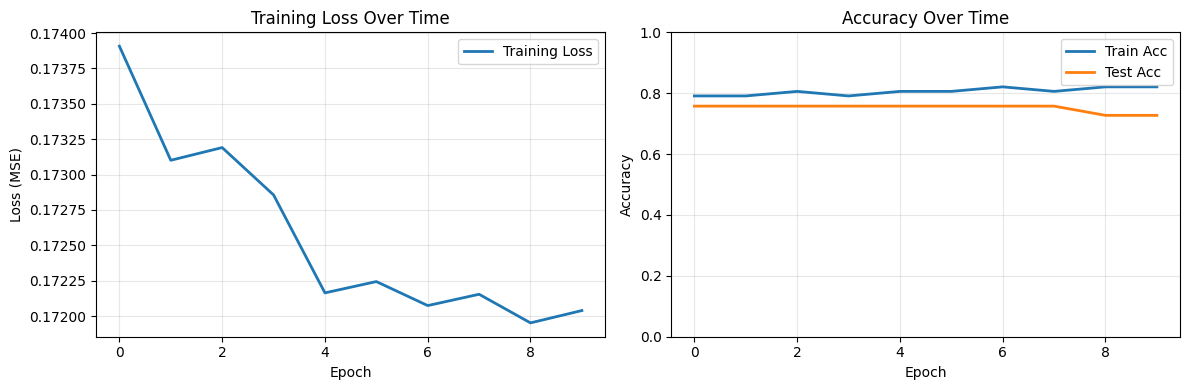

(<Figure size 1200x400 with 2 Axes>,
 (<Axes: title={'center': 'Training Loss Over Time'}, xlabel='Epoch', ylabel='Loss (MSE)'>,
  <Axes: title={'center': 'Accuracy Over Time'}, xlabel='Epoch', ylabel='Accuracy'>))

In [ ]:

def plot_training_simple(loss_list, train_acc_list, test_acc_list, savepath=None):
    # Koruma
    if (not loss_list) or (not train_acc_list) or (not test_acc_list):
        raise ValueError("Listeler boş olamaz.")
    m = min(len(loss_list), len(train_acc_list), len(test_acc_list))
    loss_list = loss_list[:m]
    train_acc_list = train_acc_list[:m]
    test_acc_list  = test_acc_list[:m]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Loss
    ax1.plot(loss_list, linewidth=2, label='Training Loss')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss (MSE)')
    ax1.set_title('Training Loss Over Time')
    ax1.grid(True, alpha=0.3); ax1.legend()

    # Accuracy
    ax2.plot(train_acc_list, linewidth=2, label='Train Acc')
    ax2.plot(test_acc_list,  linewidth=2, label='Test Acc')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
    ax2.set_title('Accuracy Over Time')
    ax2.grid(True, alpha=0.3); ax2.legend(); ax2.set_ylim(0, 1)

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, bbox_inches='tight', dpi=150)
    plt.show()
    return fig, (ax1, ax2)


plot_training_simple(losses, train_accs, test_accs)


#### Simülatörde eğittik

AerSimulator ile parametreleri (θ) optimize ettik.

Gradient’i finite-difference yöntemiyle hesapladık.

Eğitim sonucunda bir optimal_theta bulduk.

In [ ]:
# --- V1/V2 ile uyumlu p(1) çıkarıcı ---
def _p1_from_quasi(qd):
    # V1: QuasiDistribution
    try:
        bp = qd.binary_probabilities()
        return float(bp.get('1', bp.get(1, 0.0)))
    except Exception:
        return float(qd.get('1', qd.get(1, 0.0)))  # bazı sürümlerde dict

def _p1_from_counts(counts):
    tot = sum(counts.values()) or 1
    # Tek cbit ölçtüğümüz için anahtarlar '0'/'1' olmalı
    return float(counts.get('1', counts.get(1, 0)))/tot

def extract_p1_list_any(result):
    """
    Sampler V1 (SamplerResult.quasi_dists) ve
    Sampler V2 (PrimitiveResult -> SamplerPubResult) için sağlam p(1) listesi.
    """
    # --- V1 yolu: SamplerResult.quasi_dists ---
    if hasattr(result, "quasi_dists"):
        return [_p1_from_quasi(qd) for qd in result.quasi_dists]

    # --- V2 yolu: PrimitiveResult / SamplerPubResult listesi ---
    out = []
    try:
        for pub in result:  # result[0], result[1], ...
            # 1) En kolayı: tüm kayıtları birleştir
            counts = None
            try:
                jd = pub.join_data()                 # V2 önerilen yol
                if hasattr(jd, "get_counts"):
                    counts = jd.get_counts()
            except Exception:
                pass

            # 2) Alternatif: data.meas.* üzerinden
            if counts is None:
                data = getattr(pub, "data", None)
                meas = getattr(data, "meas", None) if data is not None else None
                if meas is not None:
                    try:
                        # bazı build’lerde direkt olasılık döner
                        bp = meas.binary_probabilities()
                        out.append(float(bp.get('1', bp.get(1, 0.0))))
                        continue
                    except Exception:
                        try:
                            counts = meas.get_counts()
                        except Exception:
                            counts = None

            if counts is not None:
                out.append(_p1_from_counts(counts))
                continue

        if out:
            return out
    except Exception:
        pass

    # Teşhis için: tip bilgisini göster
    raise RuntimeError(
        f"Result formatı desteklenmiyor. type(result)={type(result)}; "
        "Bu durumda result[0] nesnesindeki .join_data() veya .data.meas.* yollarını deneyin."
    )


AMAÇ

IBM Qiskit’te Sampler sonucundan p(1) olasılıklarını çekmek.
Ama sorun şu:

Eski sürüm (V1) → sonuçlar result.quasi_dists içinde gelir.

Yeni sürüm (V2) → sonuçlar PrimitiveResult / SamplerPubResult içinde gelir.
(Burada doğrudan join_data() veya data.meas.* gibi yolları kullanmak gerekir.)

👉 Bu yüzden fonksiyon “hem V1 hem V2 formatını tanıyıp doğru yerden p(1) değerini bulmaya” çalışıyor.

In [ ]:

# --- 2) Devre bağlama  ---
def make_bound_circuits_hw(X_batch, theta_vals):
    base = tqc_hw
    circs = []
    for x in X_batch:
        bind = {phi[i]: float(x[i]) for i in range(N)}
        bind |= {theta[i]: float(theta_vals[i]) for i in range(N)}
        circs.append(base.assign_parameters(bind, inplace=False))
    return circs


Verilen bir veri batch’i (X_batch) ve öğrenilmiş parametreler (theta_vals) ile, transpile edilmiş şablon devre (tqc_hw) üzerine bu parametreleri bağlamak ve çalıştırmaya hazır devre listesi döndürmek.

In [ ]:
# --- 3) Job gönder (job_id değil, job döndür) ---

def submit_hw_job(X_batch, theta_vals, shots=256):
    circs = make_bound_circuits_hw(X_batch, theta_vals)
    job = Sampler(backend=backend).run(circs, shots=shots)
    print("HW Job ID:", job.job_id())
    return job   # <— ÖNEMLİ: job_id değil

#Donanımda deneyi başlatır, job nesnesini geri verir.

In [ ]:
# --- 4) Accuracy: job veya job_id ile çalışabilen iki kısa yardımcı ---
def fetch_hw_accuracy_from_job(job, Y_slice, threshold=0.50):
    res = job.result()
    p1 = extract_p1_list_any(res)
    m = min(len(p1), len(Y_slice))
    preds = (np.array(p1[:m]) >= threshold).astype(int)
    acc = (preds == np.array(Y_slice[:m], int)).mean()
    return float(acc), p1[:m], preds.tolist()

#Job nesnesinden sonuçları alır, accuracy hesaplar.



def fetch_hw_accuracy_from_id(job_id, Y_slice, threshold=0.50):
    job = service.job(job_id)
    return fetch_hw_accuracy_from_job(job, Y_slice, threshold)

#Eski job ID’lerinden de accuracy hesaplamanı sağlar. BURAYI İNCELE

In [ ]:
theta_vals = optimal_theta
subset = 8
job = submit_hw_job(X_test_s[:subset], theta_vals, shots=256)
acc_hw, p1_hw, preds_hw = fetch_hw_accuracy_from_job(job, Y_test[:subset], threshold=0.50)
print(f"HW accuracy (subset={len(p1_hw)}): {acc_hw:.3f}")


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)


HW Job ID: [REDACTED_JOB_ID]
HW accuracy (subset=8): 0.625


#### Donanımda inference yaptık

IBM’in gerçek cihazını (ör. ibm_brisbane) seçtik.

Küçük bir test subset’ini (8 örnek) çalıştırdık.

Sampler ile her örnek için p(1) değerlerini aldık.

In [ ]:
print("Backend:", backend.name)
print("p1_hw:", [round(p, 3) for p in p1_hw])
print("preds_hw:", preds_hw)
print("y_true:", list(map(int, Y_test[:len(p1_hw)])))


Backend: ibm_brisbane
p1_hw: [0.555, 0.602, 0.488, 0.531, 0.43, 0.246, 0.301, 0.422]
preds_hw: [1, 1, 0, 1, 0, 0, 0, 0]
y_true: [1, 0, 1, 0, 0, 0, 0, 0]


In [ ]:

def best_threshold(p1, y_true, grid=np.linspace(0.40, 0.65, 11)):
    y_true = np.array(y_true[:len(p1)], int)
    best = (None, -1.0)
    for t in grid:
        preds = (np.array(p1) >= t).astype(int)
        acc = (preds == y_true).mean()
        if acc > best[1]:
            best = (t, acc)
    return best  # (threshold, accuracy)

t_opt, acc_opt = best_threshold(p1_hw, Y_test[:len(p1_hw)])
print(f"En iyi threshold: {t_opt:.2f} | Accuracy: {acc_opt:.3f}")


En iyi threshold: 0.45 | Accuracy: 0.750


#### Tahmin ve doğruluk hesapladık

p(1) ≥ threshold → 1, yoksa 0 dedik.

Tahminlerle gerçek etiketleri karşılaştırdık.

Başta threshold=0.50 ile %62.5 doğruluk çıktı.

Threshold’u 0.45’e çekince doğruluk %75 oldu.

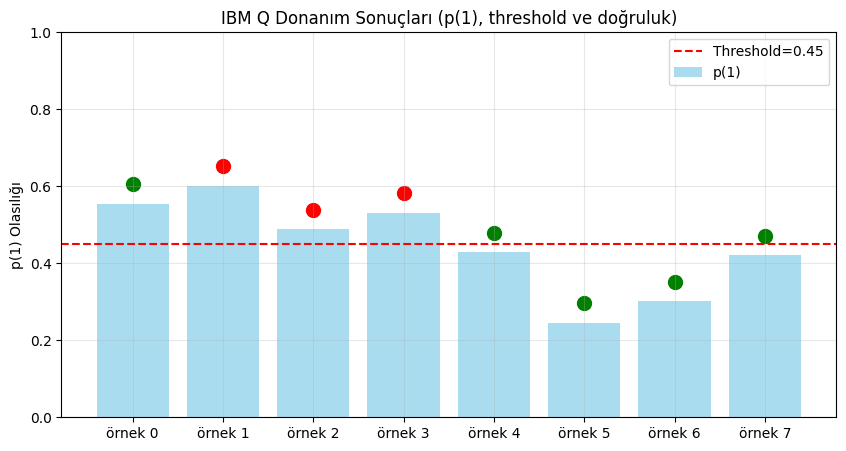

In [ ]:

def plot_hw_results(p1, y_true, preds, threshold=0.5):
    n = len(p1)
    x = np.arange(n)

    plt.figure(figsize=(10,5))

    # p(1) değerleri
    plt.bar(x, p1, color='skyblue', alpha=0.7, label="p(1)")

    # threshold çizgisi
    plt.axhline(y=threshold, color='red', linestyle='--', label=f"Threshold={threshold}")

    # Gerçek etiketleri noktalarla işaretle
    for i in range(n):
        color = "green" if preds[i]==y_true[i] else "red"
        plt.scatter(x[i], p1[i]+0.05, color=color, s=100, marker="o")

    # X ekseni
    plt.xticks(x, [f"örnek {i}" for i in range(n)])
    plt.ylim(0,1)
    plt.ylabel("p(1) Olasılığı")
    plt.title("IBM Q Donanım Sonuçları (p(1), threshold ve doğruluk)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# Çalıştır
plot_hw_results(p1_hw, Y_test[:len(p1_hw)], preds_hw, threshold=0.45)


Mavi barlar: Her örneğin p(1) değeri.

Kırmızı kesik çizgi: Threshold çizgisi.

Yeşil noktalar: Doğru tahmin edilmiş örnekler.

Kırmızı noktalar: Yanlış tahmin edilmiş örnekler.

Örnek bazlı inceleme (threshold=0.5):

p(1)=0.555 → tahmin=1, gerçek=1 → ✅ Doğru

p(1)=0.602 → tahmin=1, gerçek=0 → ❌ Yanlış

p(1)=0.488 → tahmin=0, gerçek=1 → ❌ Yanlış

p(1)=0.531 → tahmin=1, gerçek=0 → ❌ Yanlış

p(1)=0.430 → tahmin=0, gerçek=0 → ✅ Doğru

p(1)=0.246 → tahmin=0, gerçek=0 → ✅ Doğru

p(1)=0.301 → tahmin=0, gerçek=0 → ✅ Doğru

p(1)=0.422 → tahmin=0, gerçek=0 → ✅ Doğru

Toplam 5 doğru, 3 yanlış → Accuracy = 5/8 = %62.5

Aynı şey threshold=0.45 için:

Preds şu hale gelir: [1, 1, 1, 1, 0, 0, 0, 0]

Toplam 6 doğru, 2 yanlış → Accuracy = 6/8 = %75

### QNN, gerçek donanımda çalıştı ✅

Gürültü yüzünden sonuçlar çok “keskin” değil → p(1) değerleri hep 0.3–0.6 aralığında çıktı.

Doğru threshold seçmek doğruluğu artırabiliyor.

Simülatörde daha stabil iken, gerçek donanımda accuracy biraz daha düşük (bu da gürültünün etkisi).

In [ ]:
theta_vals = optimal_theta
subset = 5        # küçük parti
shots  = 128      # 100 de olur; 128 genelde stabil

jid = submit_hw_job(X_test_s[:subset], theta_vals, shots=shots)
job = watch_job(jid, interval=5, max_checks=60)

if str(job.status()) == "JobStatus.DONE":
    acc_hw, p1_hw, preds_hw = fetch_hw_accuracy(jid, Y_test[:subset], threshold=0.55)
    print("HW accuracy (subset):", acc_hw)
    print("Backend:", backend.name, "| gerçek cihaz mı?", not backend.configuration().simulator)
else:
    print("Job hazır değil; sonra şu komutla sonucu alabilirsin:")
    print(f"service.job('{jid}').result()  →  extract_p1_list(...)")


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)


KeyboardInterrupt: 

In [ ]:
#Önce küçük bir subset ile QPU doğrulaması:
# Süreni koru; uçtan uca her şey çalışıyor mu gör.

theta_vals = optimal_theta  # eğitilmiş θ ile dene (yoksa rastgele de olur)
subset = 12
acc_hw, p1_hw, preds_hw = hardware_accuracy_v1(
    X_test_s[:subset], Y_test[:subset], theta_vals,
    shots=1000, threshold=0.55
)
print("HW accuracy (subset):", acc_hw)
print("Backend:", backend.name, "| gerçek cihaz mı?", not backend.configuration().simulator)


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  sampler = Sampler(backend=backend)           # v1: backend'i doğrudan ver


HW Job ID: [REDACTED_JOB_ID]


KeyboardInterrupt: 